<a href="https://colab.research.google.com/github/g019-expert/BMEN5801_PS2/blob/main/BMEN5801_PS2_Karthik.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/g019-expert/BMEN5801_PS2.git

import os

DATA = 'BMEN5801_PS2/data'
RESULTS = 'BMEN5801_PS2/figures'
os.makedirs(RESULTS, exist_ok=True)
print(sorted(os.listdir(DATA)))

Cloning into 'BMEN5801_PS2'...
remote: Enumerating objects: 16, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 16 (delta 3), reused 9 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (16/16), 23.66 KiB | 3.94 MiB/s, done.
Resolving deltas: 100% (3/3), done.
['anemia.csv', 'insurance.csv', 'sleeplifestyle.csv']


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

## Problem 1

In [3]:
anemia = pd.read_csv(f'{DATA}/anemia.csv')
print(anemia.shape)

# data audit (referenced lecture 7) and drop rows that are exact copies (referenced code from lecture 6 ipynb)
print(f'duplicate rows: {anemia.duplicated().sum()}')
anemia = anemia.drop_duplicates().reset_index(drop=True)
print(anemia.shape)

(364, 12)
duplicate rows: 3
(361, 12)


In [4]:
# 1(a) mar/mcar
# missing values count per col and for each col with missing values compare every other

# using little's MCAR test (referenced from lecture 6)

# EM for mean/cov
def em_mean_covariance(data, max_iter=500, tol=1e-6):
    X = np.asarray(data, dtype=float)
    n, p = X.shape
    mu = np.nanmean(X, axis=0)
    sigma = np.cov(np.where(np.isnan(X), mu, X), rowvar=False, bias=True) + np.eye(p) * 1e-6
    for _ in range(max_iter):
        sum_x, sum_xx = np.zeros(p), np.zeros((p, p))
        for row in X:
            obs, miss = ~np.isnan(row), np.isnan(row)
            x = row.copy()
            if miss.any():
                s_oo_inv = np.linalg.pinv(sigma[np.ix_(obs, obs)])
                s_mo = sigma[np.ix_(miss, obs)]
                # E
                x[miss] = mu[miss] + s_mo @ s_oo_inv @ (row[obs] - mu[obs])
                xx = np.outer(x, x)
                xx[np.ix_(miss, miss)] += sigma[np.ix_(miss, miss)] - s_mo @ s_oo_inv @ s_mo.T
            else:
                xx = np.outer(x, x)
            sum_x += x
            sum_xx += xx
        # M
        new_mu = sum_x / n
        new_sigma = sum_xx / n - np.outer(new_mu, new_mu) + np.eye(p) * 1e-8
        change = max(np.abs(new_mu - mu).max(), np.abs(new_sigma - sigma).max())
        mu, sigma = new_mu, new_sigma
        if change < tol:
            break
    return mu, sigma

def littles_mcar_test(data):
    X = data.select_dtypes(include=np.number).to_numpy(dtype=float)
    mu, sigma = em_mean_covariance(X)
    patterns, inverse = np.unique(~np.isnan(X), axis=0, return_inverse=True)
    chi_sq, df_sum = 0, 0 # chi square over missing patterns
    for k, pattern in enumerate(patterns):
        rows = X[inverse.ravel() == k][:, pattern]
        diff = rows.mean(axis=0) - mu[pattern]
        chi_sq += len(rows) * diff @ np.linalg.pinv(sigma[np.ix_(pattern, pattern)]) @ diff
        df_sum += pattern.sum()
    dof = df_sum - X.shape[1]
    return chi_sq, dof, stats.chi2.sf(chi_sq, dof), len(patterns)

print(anemia.isna().sum().to_string(), '\n')

# H0 = MCAR and reject is p > .05
for name, d in [('all features', anemia), ('all features without PCV', anemia.drop(columns='PCV'))]:
    chi_sq, dof, p, n_pat = littles_mcar_test(d)
    print(f'little test:- {name}: chi2 = {chi_sq:.1f}, df = {dof}, p = {p:.1e} ({n_pat} missing patterns)')

Age       18
Sex       18
RBC       18
PCV       62
MCV       18
MCH       18
MCHC      18
RDW       18
WBC       18
PLT       18
HGB       18
Anemia     0 

little test:- all features: chi2 = 572.9, df = 479, p = 2.0e-03 (49 missing patterns)
little test:- all features without PCV: chi2 = 305.0, df = 355, p = 9.7e-01 (40 missing patterns)


In [5]:
# judgement call, mark rows with PCV missing and compare the other CBC features
CBC = ['RBC', 'PCV', 'MCV', 'MCH', 'MCHC', 'RDW', 'WBC', 'PLT', 'HGB']
pcv_flag = anemia['PCV'].isna()
rows = []
for c in [c for c in CBC if c != 'PCV']:
    a, b = anemia.loc[pcv_flag, c].dropna(), anemia.loc[~pcv_flag, c].dropna()
    rows.append({'feature': c, 'mean if PCV missing': a.mean(), 'mean if PCV observed': b.mean(),
                 'p (mann-whitney)': stats.mannwhitneyu(a, b).pvalue})
print('\n' + pd.DataFrame(rows).sort_values('p (mann-whitney)').to_string(index=False, formatters={
    'mean if PCV missing': '{:.2f}'.format, 'mean if PCV observed': '{:.2f}'.format,
    'p (mann-whitney)': '{:.1e}'.format}))

# PCV missing rate across MCV ranges
mcv_bins = pd.cut(anemia['MCV'], [0, 75, 80, 85, 90, 200], right=False)
print('\nfraction of PCV missing by MCV range (fL):')
print(pcv_flag.groupby(mcv_bins, observed=True).agg(['size', 'mean']).round(2).to_string())


feature mean if PCV missing mean if PCV observed p (mann-whitney)
    MCV               77.86                89.40          1.7e-20
    MCH               26.04                28.72          1.0e-05
    HGB               11.03                12.11          1.8e-03
    RDW               16.18                15.62          9.3e-03
    WBC               11.04                 9.86          1.6e-01
    PLT              234.29               218.16          2.4e-01
    RBC                4.37                 4.26          2.8e-01
   MCHC               32.36                32.03          8.8e-01

fraction of PCV missing by MCV range (fL):
           size  mean
MCV                  
[0, 75)      28  0.61
[75, 80)     26  0.54
[80, 85)     61  0.36
[85, 90)    112  0.05
[90, 200)   116  0.02


3 rows were exact duplicates so removed them (361 patients). little's MCAR test (refernced from lecture 6) on all features gives chi2 = 572.9, df = 479, p = 0.002 < 0.05, so not MCAR. without PCV the test gives p = 0.97, so the rest of the missing values look random and the problem is PCV. MAR has no stat test so its a judgement call, I marked rows where PCV is missing and compared the other CBC features. MCV is the biggest gap, 77.9 fL when PCV is missing vs 89.4 fL when observed (p = 1.7e-20). PCV is missing for 54-61% of patients with MCV < 80 fL but only 2-5% with MCV >= 85 fL. PCV missingness depends on an observed value (MCV) so the data are **MAR**, and PCV's missingness is most associated with MCV. MCH also differs but is much weaker and moves with MCV.

In [8]:
# 1(b)
# outliers per feature  (i) IQR fences and (ii) modified z-scores (referenced lecture 6)
#

rows, iqr_out, mz_out = [], {}, {}
for c in CBC:
    x = anemia[c].dropna()
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    # outlier if x < Q1 - 1.5*IQR or x > Q3 + 1.5*IQR
    iqr_out[c] = x.index[(x < q1 - 1.5*iqr) | (x > q3 + 1.5*iqr)]

    med = x.median()
    mad = (x - med).abs().median()
    # m_i = 0.6745*(x_i - median)/MAD, outlier if |m_i| > 3.5
    mz_out[c] = x.index[(0.6745 * (x - med) / mad).abs() > 3.5]

    both = iqr_out[c].intersection(mz_out[c])
    rows.append({'feature': c,
                 'IQR fences': f'[{q1 - 1.5*iqr:.1f}, {q3 + 1.5*iqr:.1f}]', 'n IQR': len(iqr_out[c]),
                 'mod-Z bounds': f'[{med - 3.5*mad/0.6745:.1f}, {med + 3.5*mad/0.6745:.1f}]', 'n mod-Z': len(mz_out[c]),
                 'both': len(both), 'IQR only': len(iqr_out[c]) - len(both), 'mod-Z only': len(mz_out[c]) - len(both)})

out_tbl = pd.DataFrame(rows)
print(out_tbl.to_string(index=False))
print(f'\ntotal marked: IQR {out_tbl["n IQR"].sum()}, mod-Z {out_tbl["n mod-Z"].sum()}, '
      f'both {out_tbl["both"].sum()}, mod-Z only {out_tbl["mod-Z only"].sum()}')

feature     IQR fences  n IQR   mod-Z bounds  n mod-Z  both  IQR only  mod-Z only
    RBC     [2.3, 6.3]     12     [1.7, 6.9]        1     1        11           0
    PCV   [19.2, 56.6]      5   [13.6, 60.4]        2     2         3           0
    MCV  [69.7, 105.3]     23  [64.4, 111.2]       16    16         7           0
    MCH   [20.1, 36.7]     18   [17.8, 38.6]       10    10         8           0
   MCHC   [25.8, 37.8]     22   [23.9, 39.5]        6     6        16           0
    RDW    [9.9, 19.9]     20    [8.2, 21.6]       15    15         5           0
    WBC   [-0.8, 17.4]     26   [-3.3, 19.5]       23    23         3           0
    PLT [-19.5, 440.5]     12 [-84.6, 496.6]        7     7         5           0
    HGB    [6.4, 17.6]      6    [4.8, 19.4]        3     3         3           0

total marked: IQR 144, mod-Z 83, both 83, mod-Z only 0


All 9 CBC features (found in cell 5) have outliers with both methods. IQR fencing marked 144 values and modified Z-score (|M| > 3.5) marked 83.
also, the two methods do not find the same outliers. Every point marked by modified Z is also marked by IQR (83 of 83), but IQR marked 61 extra.

Because of fewer marked points modified Z-score is more conservative. its cutoff 3.5 puts the bounds at median +/- 3.5*MAD/0.6745. modified Z only flags points much further from the center.
limited this to the 9 CBC features. since Sex is 0/1 its MAD is 0 and the modified Z-score isn't defined for it. Age has no outliers under either method and its range is 11 to 89.
IQR fence lands at 0.674std + 1.5 x 1.34std = 2.70std, and the modified-Z cutoff is 3.5std


missing HGB: 18 of 361
known relationship: HGB = 3.19 + 2.04*RBC (r = 0.75, n = 325)

MAE vs RBC-HGB relationship (g/dL):
kNN       0.920
MICE      1.268
mean      1.397
median    1.404

best: kNN


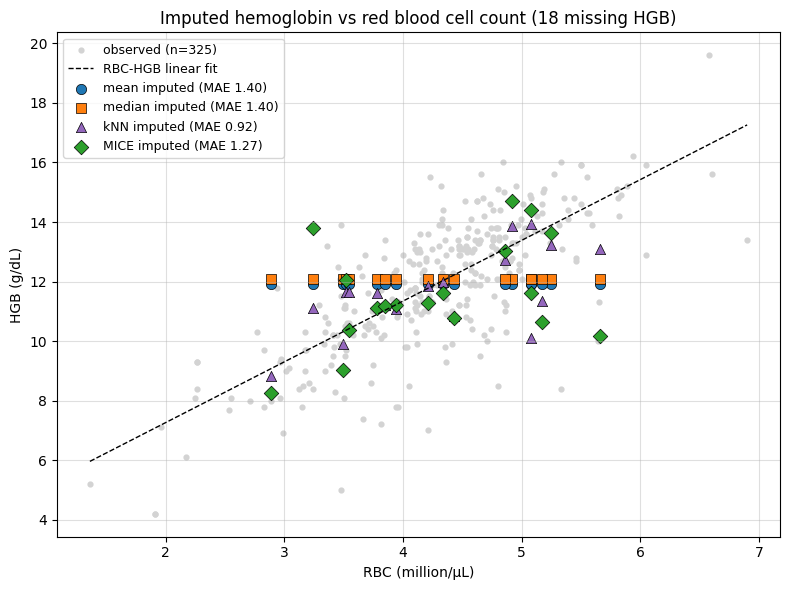

In [9]:
# 1(c)
# given: impute missing HGB using  mean, median, kNN, MICE, (kNN and MICE use the CBC values)
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import KNNImputer, IterativeImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

hgb_miss = anemia['HGB'].isna()
print(f'missing HGB: {hgb_miss.sum()} of {len(anemia)}')

imputed = {}
imputed['mean'] = anemia['HGB'].fillna(anemia['HGB'].mean())
imputed['median'] = anemia['HGB'].fillna(anemia['HGB'].median())

# kNN is distance based so scale first then scale back (refernced lecture 6)
scaler = StandardScaler()
cbc_scaled = scaler.fit_transform(anemia[CBC])
knn_out = scaler.inverse_transform(KNNImputer(n_neighbors=5).fit_transform(cbc_scaled))
imputed['kNN'] = pd.Series(knn_out[:, CBC.index('HGB')], index=anemia.index)

# MICE
mice_out = IterativeImputer(max_iter=10, random_state=10).fit_transform(anemia[CBC])
imputed['MICE'] = pd.Series(mice_out[:, CBC.index('HGB')], index=anemia.index)

# RBC-HGB relationship and linear fit on patients using both values observed
known = anemia.dropna(subset=['RBC', 'HGB'])
rbc_hgb = LinearRegression().fit(known[['RBC']], known['HGB'])
print(f'known relationship: HGB = {rbc_hgb.intercept_:.2f} + {rbc_hgb.coef_[0]:.2f}*RBC '
      f'(r = {known["RBC"].corr(known["HGB"]):.2f}, n = {len(known)})\n')

# MAE
hgb_expected = rbc_hgb.predict(anemia.loc[hgb_miss, ['RBC']])
mae = pd.Series({name: np.mean(np.abs(v[hgb_miss] - hgb_expected)) for name, v in imputed.items()})
print('MAE vs RBC-HGB relationship (g/dL):')
print(mae.sort_values().round(3).to_string())
print(f'\nbest: {mae.idxmin()}')

styles = {'mean': ('tab:blue', 'o'), 'median': ('tab:orange', 's'),
          'kNN': ('tab:purple', '^'), 'MICE': ('tab:green', 'D')}

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(known['RBC'], known['HGB'], s=12, c='lightgray', label=f'observed (n={len(known)})')
rbc_line = np.linspace(anemia['RBC'].min(), anemia['RBC'].max(), 100)
ax.plot(rbc_line, rbc_hgb.predict(pd.DataFrame({'RBC': rbc_line})), 'k--', lw=1, label='RBC-HGB linear fit')
for name, (col, mk) in styles.items():
    ax.scatter(anemia.loc[hgb_miss, 'RBC'], imputed[name][hgb_miss], s=55, c=col, marker=mk,
               edgecolor='k', lw=0.5, label=f'{name} imputed (MAE {mae[name]:.2f})')
ax.set_xlabel('RBC (million/µL)')
ax.set_ylabel('HGB (g/dL)')
ax.set_title(f'Imputed hemoglobin vs red blood cell count ({hgb_miss.sum()} missing HGB)')
ax.grid(True, alpha=0.4)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(f'{RESULTS}/p1c_hgb_imputation.png', dpi=200, bbox_inches='tight')
plt.show()

18 patients are missing HGB. kNN and MICE use the 9 CBC values.
known RBC-HGB relationship from the 325 patients using both values is HGB = 3.19 + 2.04·RBC (r = 0.75).
kNN does the best job (MAE 0.92), then MICE (1.27), mean (1.40), median (1.40). mean and median give every patient the same value (about 12), so they ignore RBC and appears as a flat row in the plot above. intuitively, why kNN did best is becaues kNN fills each value from patients with similar CBC values (mimics the RBC-HGB relation the closest).

## Problem 2

In [10]:
insurance = pd.read_csv(f'{DATA}/insurance.csv')
print(insurance.shape)
print(insurance['smoker'].value_counts().to_string())
print(f'missing values: {insurance.isna().sum().sum()}, duplicate rows: {insurance.duplicated().sum()}')

(1338, 4)
smoker
no     1064
yes     274
missing values: 0, duplicate rows: 1


age, smoker=yes: theta_0 =   20294.1, theta_1 =   305.2, R^2 = 0.136
age, smoker= no: theta_0 =   -2091.4, theta_1 =   267.2, R^2 = 0.394
bmi, smoker=yes: theta_0 =  -13186.6, theta_1 =  1473.1, R^2 = 0.650
bmi, smoker= no: theta_0 =    5879.4, theta_1 =    83.4, R^2 = 0.007


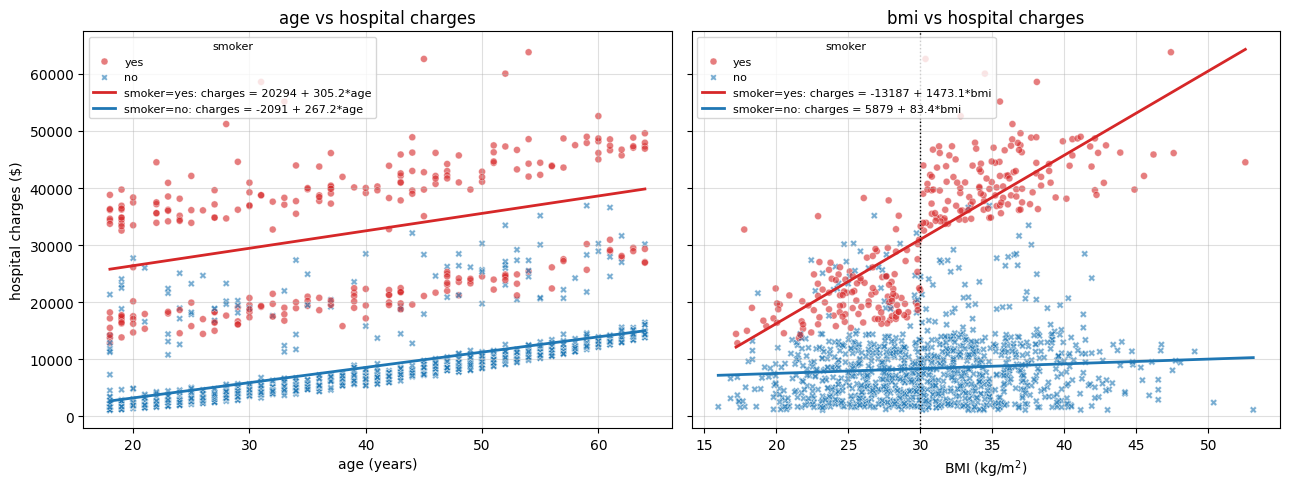


smokers, charges by BMI >= 30 (obese):
       size     mean
bmi                 
False   129  21363.0
True    145  41558.0

non-smokers above age trend: 94 of 1064
          age   bmi  charges
charges                     
False    39.4  30.6   7070.1
True     39.4  31.1  22511.1


In [11]:
# 2(a)
# sns scatter age vs charges and bmi vs charges, smoker status, lin reg (referenced lecture 9)
# on each smoker group theta_0 (bias) and theta_1 (slope)
from sklearn.linear_model import LinearRegression

palette = {'yes': 'tab:red', 'no': 'tab:blue'}
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, x, xlabel in zip(axes, ['age', 'bmi'], ['age (years)', 'BMI (kg/m$^2$)']):
    sns.scatterplot(data=insurance, x=x, y='charges', hue='smoker', style='smoker',
                    palette=palette, alpha=0.6, s=25, ax=ax)
    for s in ['yes', 'no']:
        g = insurance[insurance['smoker'] == s]
        lin_reg = LinearRegression().fit(g[[x]], g['charges'])
        x_line = pd.DataFrame({x: np.linspace(g[x].min(), g[x].max(), 100)})
        ax.plot(x_line[x], lin_reg.predict(x_line), color=palette[s], lw=2,
                label=f'smoker={s}: charges = {lin_reg.intercept_:.0f} + {lin_reg.coef_[0]:.1f}*{x}')
        print(f'{x:>3}, smoker={s:>3}: theta_0 = {lin_reg.intercept_:9.1f}, theta_1 = {lin_reg.coef_[0]:7.1f}, '
              f'R^2 = {lin_reg.score(g[[x]], g["charges"]):.3f}')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('hospital charges ($)')
    ax.set_title(f'{x} vs hospital charges')
    ax.grid(True, alpha=0.4)
    ax.legend(title='smoker', fontsize=8, title_fontsize=8, loc='upper left')

axes[1].axvline(30, color='k', ls=':', lw=1)  # BMI 30 = obese
fig.tight_layout()
fig.savefig(f'{RESULTS}/p2a_charges_scatter.png', dpi=200, bbox_inches='tight')
plt.show()

# what factors for the bimodal distribtn in hospital charges
smk = insurance[insurance['smoker'] == 'yes']
print('\nsmokers, charges by BMI >= 30 (obese):')
print(smk.groupby(smk['bmi'] >= 30)['charges'].agg(['size', 'mean']).round(0).to_string())

non = insurance[insurance['smoker'] == 'no']
age_fit = LinearRegression().fit(non[['age']], non['charges'])
upper = (non['charges'] - age_fit.predict(non[['age']])) > 5000
print(f'\nnon-smokers above age trend: {upper.sum()} of {len(non)}')
print(non.groupby(upper)[['age', 'bmi', 'charges']].mean().round(1).to_string())

fators contributing for bimodal distribtn for

* smoker: factor is BMI. Becaue smokers with BMI >= 30 average \$41,558 vs $21,363 for BMI < 30, and the smoker points jump up at BMI 30 in the bmi vs charges plot.

* non-smoker: charges sit on one tight band that goes up with age (R^2 = 0.39), and BMI barely matters (R^2 = 0.007). Maybe other health conditions serve as factors for non-smokers

------ train/test on same data (n = 1338) ------
[[1026   38]
 [  25  249]]
              precision    recall  f1-score   support

  non-smoker     0.9762    0.9643    0.9702      1064
      smoker     0.8676    0.9088    0.8877       274

    accuracy                         0.9529      1338
   macro avg     0.9219    0.9365    0.9290      1338
weighted avg     0.9540    0.9529    0.9533      1338

>>>> Overall accuracy: 0.9529 (95.29%)

------ train 75/test 25 (n = 335) ------
[[256   9]
 [  8  62]]
              precision    recall  f1-score   support

  non-smoker     0.9697    0.9660    0.9679       265
      smoker     0.8732    0.8857    0.8794        70

    accuracy                         0.9493       335
   macro avg     0.9215    0.9259    0.9236       335
weighted avg     0.9495    0.9493    0.9494       335

>>>> Overall accuracy: 0.9493 (94.93%)



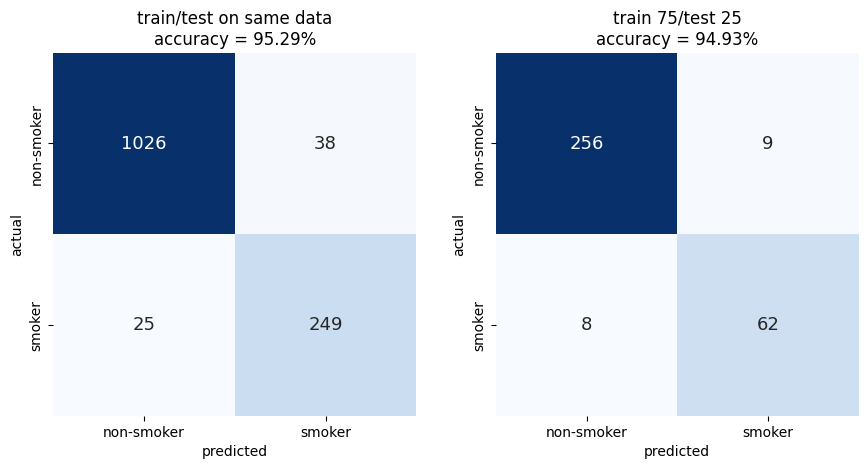

In [12]:
# 2(b)
# log reg model smoker vs non-smoker from age, bmi, charges
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn import metrics

X = insurance[['age', 'bmi', 'charges']]
# smoker = 1
y = (insurance['smoker'] == 'yes').astype(int)
labels = ['non-smoker', 'smoker']

# train and test on same data
scaler = StandardScaler()
X_all = scaler.fit_transform(X)
log_reg = LogisticRegression().fit(X_all, y)
pred_same = log_reg.predict(X_all)

# train 75% / test 25% w random_state = 10, scaler fit on training part only so no test info leaks in (referenced lecture 7)
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=10)
scaler_tr = StandardScaler().fit(x_train)
log_reg_split = LogisticRegression().fit(scaler_tr.transform(x_train), y_train)
pred_split = log_reg_split.predict(scaler_tr.transform(x_test))

cases = [('train/test on same data', y, pred_same), ('train 75/test 25', y_test, pred_split)]

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, (name, y_true, y_pred) in zip(axes, cases):
    cm = metrics.confusion_matrix(y_true, y_pred)
    acc = metrics.accuracy_score(y_true, y_pred)
    print(f'------ {name} (n = {len(y_true)}) ------')
    print(cm)
    print(metrics.classification_report(y_true, y_pred, target_names=labels, digits=4))
    print(f'>>>> Overall accuracy: {acc:.4f} ({100*acc:.2f}%)\n')

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, square=True,
                xticklabels=labels, yticklabels=labels, annot_kws={'size': 13}, ax=ax)
    ax.set_xlabel('predicted')
    ax.set_ylabel('actual')
    ax.set_title(f'{name}\naccuracy = {100*acc:.2f}%')

fig.tight_layout()
fig.savefig(f'{RESULTS}/p2b_confusion_matrices.png', dpi=200, bbox_inches='tight')
plt.show()

Overall accuracy is lower on when using the split because when model is tested on the same data it has trained on, the model is being scored on patients it already saw and fit its parameters to, so the score is more memorized. But with using the 75/25 split the 335 test patients were never used for fitting the parameters, so the overall accuracy shows how the model does on new patients (which is important because we want the model to be more generalizable)

## Problem 3

In [13]:
sleep = pd.read_csv(f'{DATA}/sleeplifestyle.csv')
print(sleep.shape, f'missing values: {sleep.isna().sum().sum()}')
print(sleep['Sleep Disorder'].value_counts().to_string())

(374, 13) missing values: 0
Sleep Disorder
Regular Sleep    219
Sleep Apnea       78
Insomnia          77


12 features: ['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'Systolic', 'Diastolic', 'Heart Rate', 'Daily Steps', 'Gender_Male', 'BMI Category_Obese', 'BMI Category_Overweight']
train n = 280, test n = 94: {'Regular Sleep': 57, 'Insomnia': 21, 'Sleep Apnea': 16}

------ no regularization ------
[[53  1  3]
 [ 1 18  2]
 [ 2  0 14]]
accuracy = 90.43%, coefficients = 0: 0 of 36, largest |coef| = 4.40



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


------ ridge regression (L2) ------
[[53  1  3]
 [ 1 17  3]
 [ 2  0 14]]
accuracy = 89.36%, coefficients = 0: 0 of 36, largest |coef| = 1.00



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(


------ lasso regression(L1) ------
[[53  1  3]
 [ 1 17  3]
 [ 2  0 14]]
accuracy = 89.36%, coefficients = 0: 18 of 36, largest |coef| = 1.45

------ elastic net regression ------
[[53  1  3]
 [ 1 17  3]
 [ 2  0 14]]
accuracy = 89.36%, coefficients = 0: 13 of 36, largest |coef| = 1.29



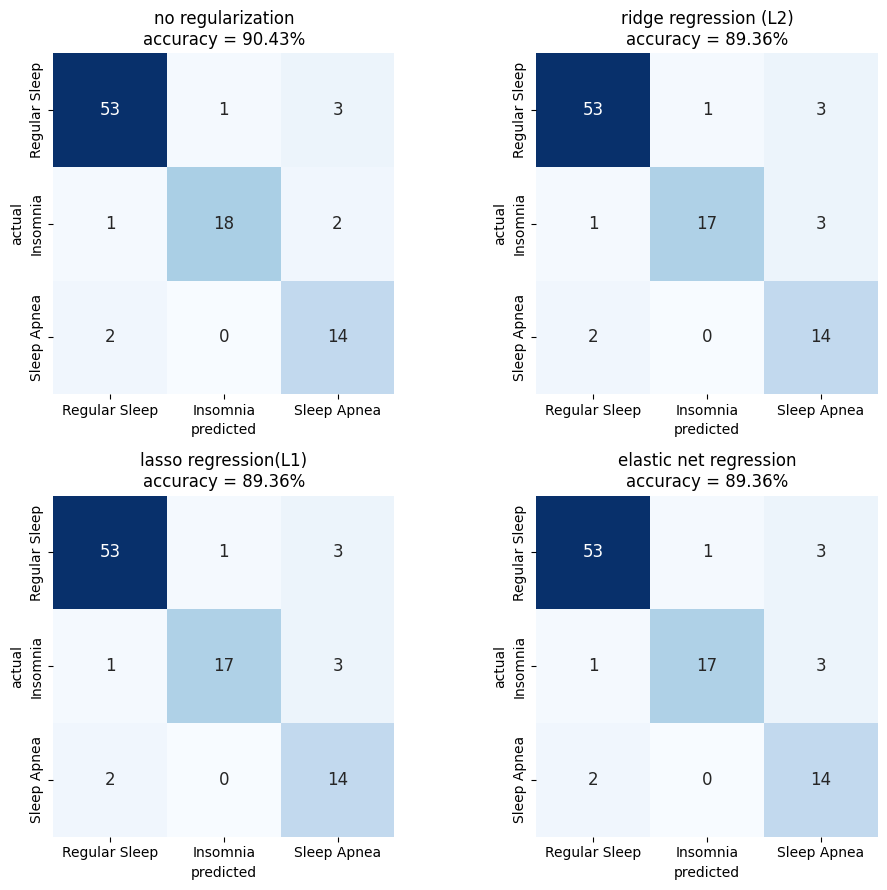

In [14]:
# multinomial log reg for regular sleep, insomnia,  sleep apnea
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn import metrics

# PersonID ignored, and alsop gender and BMI are text so both are one-hot encoded
X = pd.get_dummies(sleep.drop(columns=['Person ID', 'Sleep Disorder']),
                   columns=['Gender', 'BMI Category'], drop_first=True, dtype=int)
y = sleep['Sleep Disorder']
classes = ['Regular Sleep', 'Insomnia', 'Sleep Apnea']
print(f'{X.shape[1]} features: {list(X.columns)}')

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=10)
# gradient based so features scaled, scaler fit on training part only (referenced lecture 7)
scaler = StandardScaler().fit(x_train)
x_train_s, x_test_s = scaler.transform(x_train), scaler.transform(x_test)
print(f'train n = {len(y_train)}, test n = {len(y_test)}: {y_test.value_counts().to_dict()}\n')

models = {
    'no regularization': dict(penalty=None),
    'ridge regression (L2)': dict(penalty='l2', l1_ratio=0),
    'lasso regression(L1)': dict(penalty='l1', l1_ratio=1),
    'elastic net regression': dict(penalty='elasticnet', l1_ratio=0.5),
}

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, (name, params) in zip(axes.ravel(), models.items()):
    model = LogisticRegression(solver='saga', max_iter=10000, **params).fit(x_train_s, y_train)
    pred = model.predict(x_test_s)
    cm = metrics.confusion_matrix(y_test, pred, labels=classes)
    acc = metrics.accuracy_score(y_test, pred)
    print(f'------ {name} ------')
    print(cm)
    print(f'accuracy = {100*acc:.2f}%, coefficients = 0: {(np.abs(model.coef_) < 1e-6).sum()} of {model.coef_.size}, '
          f'largest |coef| = {np.abs(model.coef_).max():.2f}\n')

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, square=True,
                xticklabels=classes, yticklabels=classes, annot_kws={'size': 12}, ax=ax)
    ax.set_xlabel('predicted')
    ax.set_ylabel('actual')
    ax.set_title(f'{name}\naccuracy = {100*acc:.2f}%')

fig.tight_layout()
fig.savefig(f'{RESULTS}/p3_confusion_matrices.png', dpi=200, bbox_inches='tight')
plt.show()

All 4 models are multinomial logistic regression with the same solver

* (i), accuracy = 90.43%
* (ii-iv), accuracy = 89.36%

Reason for the above accuracy change is the one insominia patient (i) gets right and (ii-iv) labels them apnea

The reason they differ is because logistic regression gives each feature a weight and adds them to pick which class. With no regularization the model can make these weights as big as it wants to fit the training patients as closely as possible like the coeff 4.40 . All of ridge, lasso and elastic net add a cost for big weights to keep the weights small (1 to 1.45). lasso and elastic set 18 and 13 respectively of the 36 weights to 0 meaning they stop using some features at all.

In theory, smaller weights in a model means that the model makes simpler decisions. In this example a patient who sits on the edge between two classes can land on the other side (which is what happened to the one insomnia patient)